In [1]:
from datasets.BUSI import BUSI
from datasets.BUSBRA import BUSBRA
from datasets.BUS_UC import BUS_UC
from datasets.ISIC2017 import ISIC2017
from datasets.ISIC2018 import ISIC2018
from datasets.PolypDB_WLI import PolypDB_WLI
from datasets.CHAOS import CHAOS
from datasets.BRISC2025 import BRISC2025
from datasets.BKAI import BKAI
from datasets.KvasirSEG import KvasirSEG
from datasets.QaTa_COV19_v2 import QaTa_COV19_v2
from datasets.QaTa_COV19_v1 import QaTa_COV19_v1
from datasets.BTMRI import BTMRI
from datasets.NuSeC import NuSeC
from datasets.GlaS import GlaS
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import torch
import numpy as np
from metrics import *
from models.BEAFormer import BEAFormer
import torch.nn.functional as F
import utils
import os

def focus_on_mask_square(img: torch.Tensor,
                         mask: torch.Tensor,
                         padding: int = 30):
    """
    更紧凑的正方形裁剪

    img:  (H,W) 或 (3,H,W)
    mask: (H,W)
    padding: 小范围外扩

    return:
        square_cropped_img
    """
    assert mask.dim() == 2

    if img.dim() == 2:
        is_gray = True
        H, W = img.shape
    elif img.dim() == 3:
        is_gray = False
        _, H, W = img.shape
    else:
        raise ValueError("img must be (H,W) or (3,H,W)")

    coords = torch.nonzero(mask)

    if coords.shape[0] == 0:
        return img

    y_min = coords[:, 0].min().item()
    y_max = coords[:, 0].max().item()
    x_min = coords[:, 1].min().item()
    x_max = coords[:, 1].max().item()

    # 原始目标尺寸
    h = y_max - y_min + 1
    w = x_max - x_min + 1

    # 取最大边长，构造正方形
    side = max(h, w)

    # 中心点
    cy = (y_min + y_max) // 2
    cx = (x_min + x_max) // 2

    half = side // 2 + padding

    y1 = cy - half
    y2 = cy + half
    x1 = cx - half
    x2 = cx + half

    # 防越界
    if y1 < 0:
        y2 -= y1
        y1 = 0
    if x1 < 0:
        x2 -= x1
        x1 = 0
    if y2 >= H:
        shift = y2 - H + 1
        y1 -= shift
        y2 = H - 1
    if x2 >= W:
        shift = x2 - W + 1
        x1 -= shift
        x2 = W - 1

    y1 = max(0, y1)
    x1 = max(0, x1)

    # crop
    if is_gray:
        cropped = img[y1:y2+1, x1:x2+1]
    else:
        cropped = img[:, y1:y2+1, x1:x2+1]

    return cropped

def mark_boundary(img: torch.Tensor, mask: torch.Tensor):
    """
    img:  (H,W) 或 (3,H,W)
    mask: (H,W)
    """
    if img.dim() == 2:
        img = img.unsqueeze(0).repeat(3, 1, 1)
    elif img.dim() == 3 and img.shape[0] == 3:
        pass
    else:
        raise ValueError("img must be (H,W) or (3,H,W)")

    out = img.clone()
    mask_bool = mask.bool()

    # 判断数值范围
    max_val = 255 if img.max() > 1 else 1.0

    out[0][mask_bool] = max_val
    out[1][mask_bool] = 0
    out[2][mask_bool] = 0

    return out

def visualize_rgb_image(image, save_path=None, dpi=300):
    image = image.detach().cpu()
    image = image.permute(1, 2, 0)
    image_np = image.numpy()
    
    img_min, img_max = image_np.min(), image_np.max()
    image_np = (image_np - img_min) / (img_max - img_min + 1e-8)
    image_np = image_np.astype(np.float32)
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5), dpi=dpi)
    ax.imshow(image_np)
    ax.axis("off")
    plt.tight_layout(pad=0)
    
    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight', pad_inches=0)
    
    plt.show()
    plt.close(fig)


def visualize_gray_image(image, save_path=None, dpi=300, cmap='gray'):
    image = image.detach().cpu().squeeze(0)
    image_np = image.numpy()
    
    img_min, img_max = image_np.min(), image_np.max()
    image_np = (image_np - img_min) / (img_max - img_min + 1e-8)
    image_np = image_np.astype(np.float32)
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5), dpi=dpi)
    ax.imshow(image_np, cmap=cmap)
    ax.axis("off")
    plt.tight_layout(pad=0)
    
    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight', pad_inches=0)
    
    plt.show()
    plt.close(fig)

def visualize_binary_label(label, save_path=None, dpi=300):
    if torch.is_tensor(label):
        label = label.cpu().detach().numpy()
    
    if label.ndim == 3 and label.shape[0] == 1:
        label = label.squeeze(0)
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    ax.imshow(label, cmap='gray', vmin=0, vmax=1)
    ax.axis("off")
    plt.tight_layout()
    
    if save_path:
        os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight', pad_inches=0)
    
    plt.show()

def visualize_bnd_heatmap(label, save_path=None, dpi=300):
    if torch.is_tensor(label):
        label = label.cpu().detach().numpy()
    
    if label.ndim == 3 and label.shape[0] == 1:
        label = label.squeeze(0)
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    
#     im = ax.imshow(label, cmap='jet', vmin=0, vmax=1, interpolation='nearest')
    im = ax.imshow(label, cmap='viridis', vmin=0, vmax=1, interpolation='nearest')
    ax.axis("off")
    plt.tight_layout()
    
    if save_path:
        os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight', pad_inches=0)
    
    plt.show()

dev = torch.device("cuda:0")

/home/shy/.conda/envs/shy_py310/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/shy/.conda/envs/shy_py310/lib/python3.10/site-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno 101] Network is unreachable>
  data = fetch_version_info()
/home/shy/.conda/envs/shy_py310/lib/python3.10/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [2]:
db = BTMRI(root="/mnt/folder_3/shy/data/BTMRI_224x224", split="test")
loader = DataLoader(db, batch_size=1, shuffle=False)

def get_model(model_state_path: str):
    model = BEAFormer(1)
    model_state_dict = torch.load(model_state_path, map_location="cpu")
    model.load_state_dict(model_state_dict, strict=True)
    model = model.to(dev)
    model.eval()
    return model

# bad
model1 = get_model("/mnt/folder_3/shy/beaformer_ablation/outputs/btmri/no_bndsup/best_model.pth")
# good
model2 = get_model("/mnt/folder_3/shy/beaformer_ablation/outputs/btmri/run1/best_model.pth")

items = []

for idx, batch in enumerate(loader):
    label = batch["label"].squeeze(0)
    if label.sum() == 0:
        continue
        
    image = batch["image"].to(dev)
    preds1, _ = model1(image)
    preds2, _ = model2(image)
    
    dice1 = metrics_binary((preds1 > 0).long().squeeze(0).squeeze(0), label)["dice"]
    dice2 = metrics_binary((preds2 > 0).long().squeeze(0).squeeze(0), label)["dice"]
    
    items.append({"idx": idx, "dice":dice1 - dice2})

items.sort(key=lambda x:x["dice"])

39


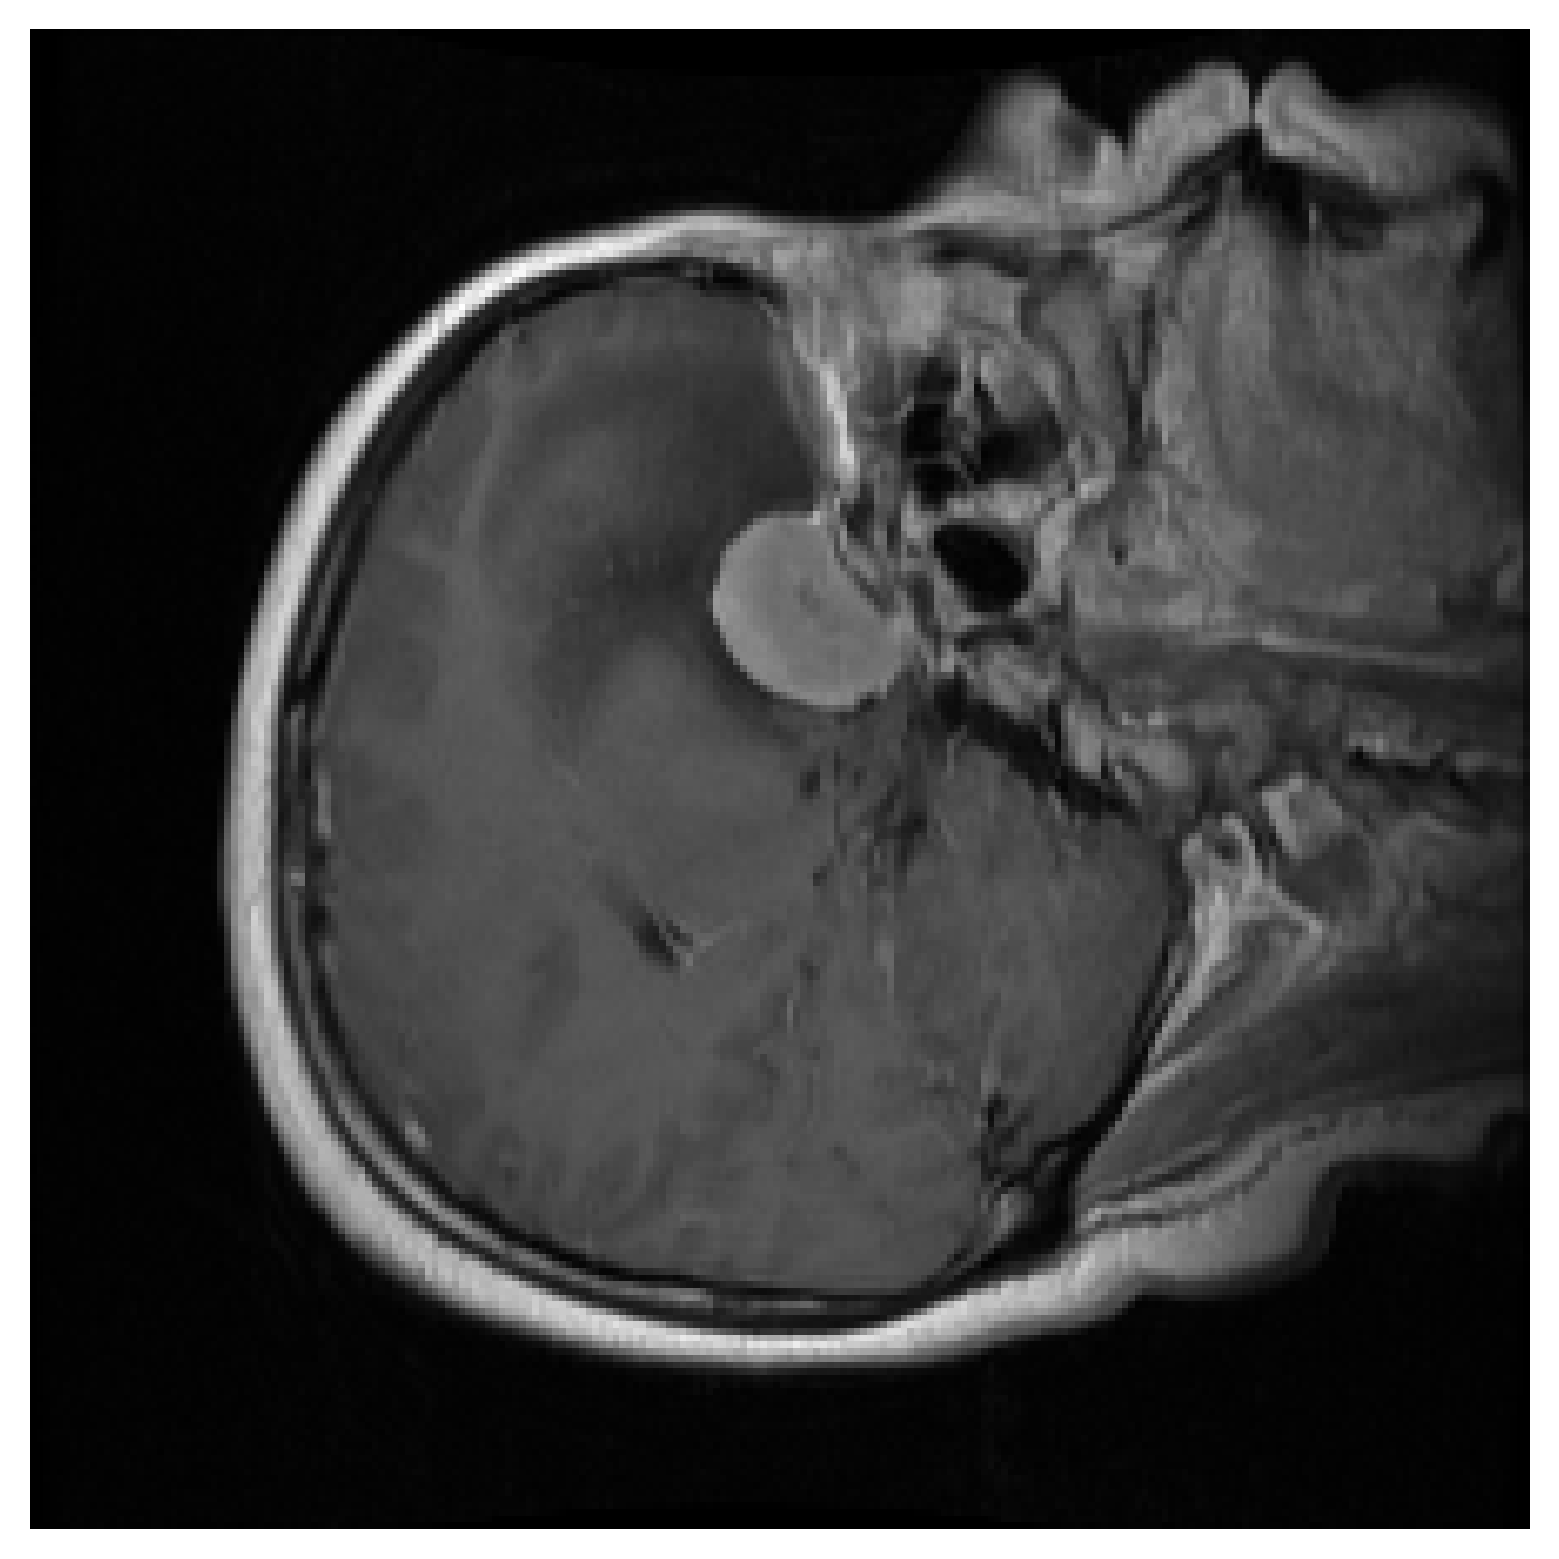

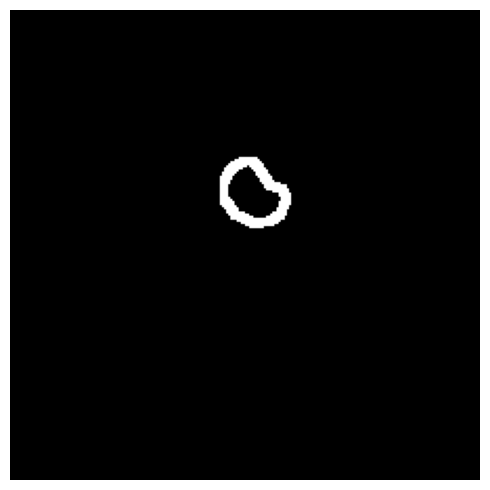

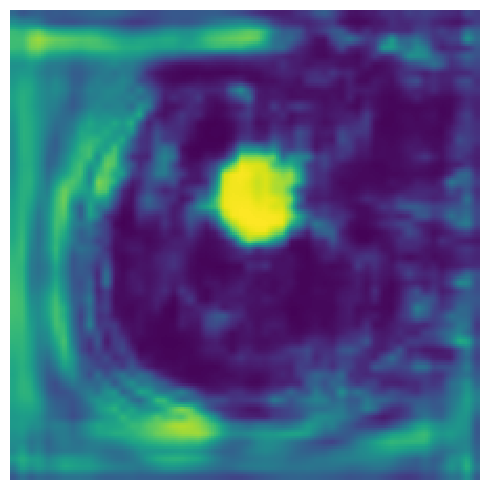

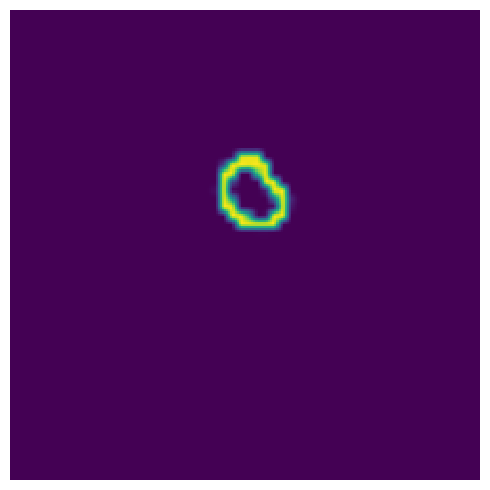

In [7]:
for i in range(len(items)):        
    if i != 39:
        continue
    print(i)
    
    batch = db[items[i]["idx"]]
    image = batch["image"].unsqueeze(0).to(dev)
    label = batch["label"]
    bnd_label = utils.get_bnd_label(label)
    
    _, g1 = model1(image)
    _, g2 = model2(image)
    g1 = g1.squeeze(0).squeeze(0)
    g2 = g2.squeeze(0).squeeze(0)

#     H, W = (224, 224)

#     aux_pred1 = F.interpolate(enc_gs[1], size=(H, W), mode="bilinear", align_corners=True).squeeze(0).squeeze(0)
#     aux_pred2 = F.interpolate(dec_gs[0], size=(H, W), mode="bilinear", align_corners=True).squeeze(0).squeeze(0)
#     aux_pred3 = F.interpolate(dec_gs[-1], size=(H, W), mode="bilinear", align_corners=True).squeeze(0).squeeze(0)
#     aux_pred1 = enc_gs[1].squeeze(0).squeeze(0)
#     aux_pred2 = dec_gs[0].squeeze(0).squeeze(0)
#     aux_pred3 = dec_gs[-1].squeeze(0).squeeze(0)


    # gray
    image = image[0][0]
#     # rgb
#     image = image[0]

    image = (image - image.min()) / (image.max() - image.min() + 1e-8)
    
    #, save_path="./pictures/intro_glas_img.png"
#     visualize_rgb_image(image, save_path="./pictures/routing_polyp_img.png")
    visualize_gray_image(image, save_path="./pictures/routing_btmri_img.png")
    
    visualize_binary_label(bnd_label, save_path="./pictures/routing_btmri_lbl.png")
    
#     marked_image = mark_boundary(image, bnd_label)
    
    # , save_path="./pictures/intro_polyp_bnd.png"
#     visualize_rgb_image(focus_on_mask_square(marked_image, bnd_label), save_path="./pictures/intro_btmri_bnd.png")
    
    # , save_path="./pictures/routing_busi_heatmap_good.png"
    visualize_bnd_heatmap(g1, save_path="./pictures/routing_btmri_heatmap_bad.png")
    visualize_bnd_heatmap(g2, save_path="./pictures/routing_btmri_heatmap_good.png")
#     visualize_binary_label(aux_pred3)